# Studi Kasus Webinar 6: Klasifikasi Penyebab Deforestasi dengan CNN
**Platform:** Google Colab · **Bahasa:** Python · **Framework:** TensorFlow/Keras

## 1. Latar belakang
Sistem peringatan kehilangan tutupan pohon seperti RADD dan GLAD membantu menunjukkan lokasi gangguan hutan, tetapi tidak selalu menjelaskan penyebab langsungnya. Materi webinar membahas penggunaan citra Sentinel-1 (radar), Sentinel-2 (optik), informasi slope, dan CNN untuk mengklasifikasikan penyebab deforestasi.

## 2. Tujuan
- Membangun contoh alur kerja klasifikasi berbasis CNN.
- Menghasilkan prediksi kelas dan probabilitas.
- Mengevaluasi model menggunakan Overall Accuracy dan Macro-F1.
- Membuat visualisasi confusion matrix dan contoh prediksi.



## Langkah 1 — Impor pustaka

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU tersedia:", bool(tf.config.list_physical_devices("GPU")))


TensorFlow: 2.21.0
GPU tersedia: False


## Langkah 2 — Buat dataset sintetis
Setiap contoh berupa patch 32×32 dengan 3 kanal. Pola dibuat berbeda-beda secara artifisial untuk tiap label. Ini **bukan** data Sentinel dan tidak menggambarkan ciri ilmiah yang tervalidasi dari setiap penyebab deforestasi.

In [2]:
CLASS_NAMES = [
    "Pertanian skala besar",
    "Pertanian skala kecil",
    "Pertambangan",
    "Pembangunan jalan",
    "Penebangan selektif",
    "Kebakaran hutan",
    "Banjir",
    "Faktor alam lainnya",
]
N_CLASSES = len(CLASS_NAMES)
IMG_SIZE = 32
CHANNELS = 3
SAMPLES_PER_CLASS = 250

def make_patch(class_id, rng, size=IMG_SIZE):
    # Basis acak untuk mensimulasikan variasi antarpengamatan.
    img = rng.normal(0.45, 0.12, (size, size, CHANNELS))
    yy, xx = np.mgrid[0:size, 0:size]

    if class_id == 0:  # blok geometris
        img[5:27, 5:27, :] += 0.25
        img[10:22, 10:22, :] -= 0.15
    elif class_id == 1:  # petak kecil
        for y in [4, 13, 22]:
            for x in [4, 13, 22]:
                img[y:y+5, x:x+5, :] += 0.22
    elif class_id == 2:  # area terang tak beraturan
        mask = ((xx-16)**2 / 95 + (yy-16)**2 / 65) < 1
        img[mask, 0] += 0.35
        img[mask, 1] += 0.18
    elif class_id == 3:  # garis seperti koridor jalan
        dist = np.abs(yy - (0.55*xx + 5))
        img[dist < 2.0, :] += 0.38
    elif class_id == 4:  # titik-titik terpisah
        for _ in range(10):
            x, y = rng.integers(2, size-2, size=2)
            img[y-1:y+2, x-1:x+2, :] -= 0.25
    elif class_id == 5:  # kanal merah lebih kuat
        blob = ((xx-16)**2 + (yy-16)**2) < 90
        img[blob, 0] += 0.4
        img[blob, 1] -= 0.12
    elif class_id == 6:  # area biru/cyan
        mask = (yy > 8) & (yy < 25) & (xx > 3) & (xx < 29)
        img[mask, 2] += 0.35
        img[mask, 0] -= 0.12
    else:  # pola gradien alami
        grad = (xx + yy) / (2 * size)
        img[:, :, 1] += 0.20 * grad

    img += rng.normal(0, 0.04, img.shape)
    return np.clip(img, 0, 1).astype("float32")

rng = np.random.default_rng(SEED)
X_list, y_list = [], []
for c in range(N_CLASSES):
    for _ in range(SAMPLES_PER_CLASS):
        X_list.append(make_patch(c, rng))
        y_list.append(c)

X = np.stack(X_list)
y = np.array(y_list, dtype="int64")
print("Bentuk X:", X.shape)
print("Bentuk y:", y.shape)
print("Jumlah kelas:", len(np.unique(y)))


Bentuk X: (2000, 32, 32, 3)
Bentuk y: (2000,)
Jumlah kelas: 8


## Langkah 3 — Lihat contoh patch sintetis

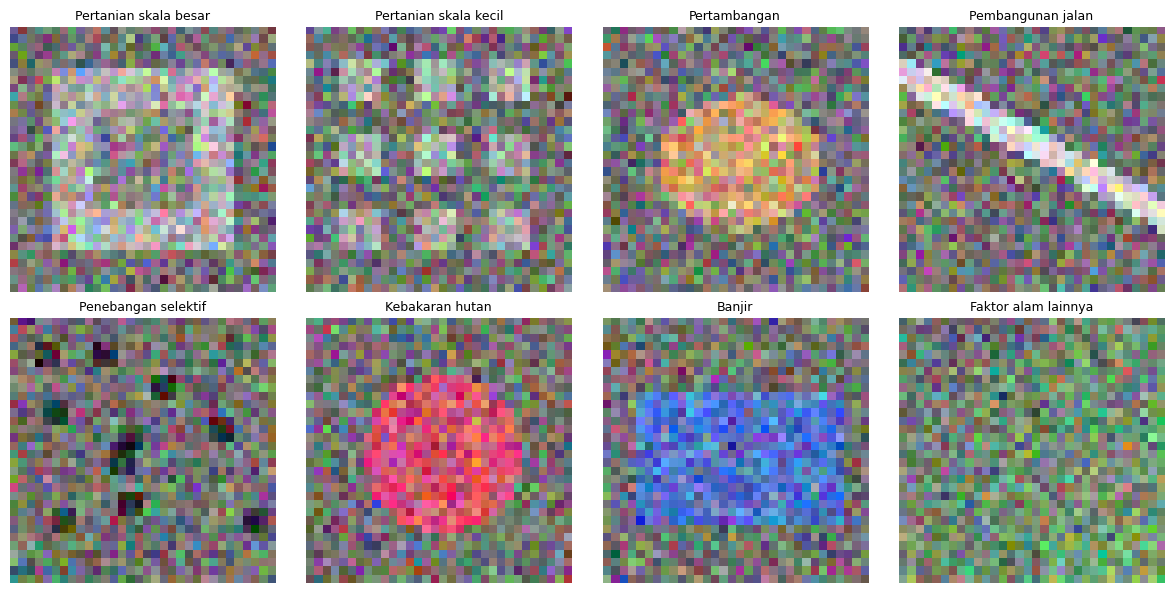

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for class_id, ax in enumerate(axes.ravel()):
    sample_idx = np.where(y == class_id)[0][0]
    ax.imshow(X[sample_idx])
    ax.set_title(CLASS_NAMES[class_id], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()


## Langkah 4 — Bagi data train, validation, dan test

In [4]:
# 70% train, 15% validation, 15% test; stratifikasi menjaga proporsi kelas.
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

print("Train:", X_train.shape, "Validation:", X_val.shape, "Test:", X_test.shape)


Train: (1400, 32, 32, 3) Validation: (300, 32, 32, 3) Test: (300, 32, 32, 3)


## Langkah 5 — Bangun dan latih CNN

In [5]:
model = keras.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, CHANNELS)),
    layers.Conv2D(16, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.30),
    layers.Dense(N_CLASSES, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=4, restore_best_weights=True
    )
]
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    callbacks=callbacks,
    verbose=1
)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,264 (110.41 KB)

 Trainable params: 28,264 (110.41 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 5s 40ms/step - accuracy: 0.1771 - loss: 2.0334 - val_accuracy: 0.2500 - val_loss: 1.9019
Epoch 2/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - accuracy: 0.4050 - loss: 1.5610 - val_accuracy: 0.6233 - val_loss: 1.1027
Epoch 3/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - accuracy: 0.6200 - loss: 0.9774 - val_accuracy: 0.8300 - val_loss: 0.6736
Epoch 4/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 68ms/step - accuracy: 0.7236 - loss: 0.6867 - val_accuracy: 0.7433 - val_loss: 0.5303
Epoch 5/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - accuracy: 0.7921 - loss: 0.5281 - val_accuracy: 0.9067 - val_loss: 0.3627
Epoch 6/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - accuracy: 0.8186 - loss: 0.4153 - val_accuracy: 0.8667 - val_loss: 0.3095
Epoch 7/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - accuracy: 0.8421 - loss: 0.3932 - val_accuracy: 0.8933 - val_loss: 0.2764
Epoch 8/20
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - accuracy: 0.8614 - loss: 0.3140 - val_accuracy: 0.9300 - v

## Langkah 6 — Visualisasikan proses pelatihan

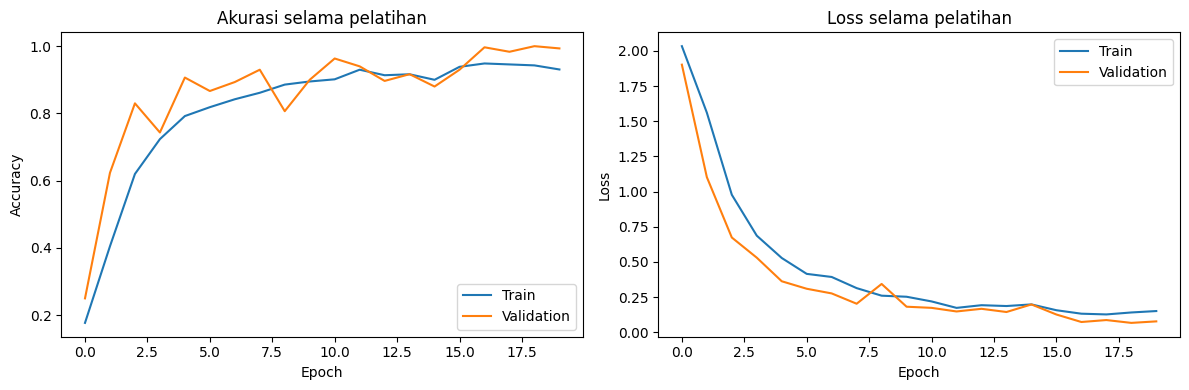

In [6]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Akurasi selama pelatihan")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Loss selama pelatihan")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.show()


## Langkah 7 — Evaluasi dengan Overall Accuracy dan Macro-F1

In [7]:
probabilities = model.predict(X_test, verbose=0)
y_pred = probabilities.argmax(axis=1)

overall_accuracy = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average="macro")

print(f"Overall Accuracy: {overall_accuracy:.3f}")
print(f"Macro-F1 Score:   {macro_f1:.3f}")
print("\nLaporan per kelas:")
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, zero_division=0))


Overall Accuracy: 1.000
Macro-F1 Score:   1.000

Laporan per kelas:
                       precision    recall  f1-score   support

Pertanian skala besar       1.00      1.00      1.00        37
Pertanian skala kecil       1.00      1.00      1.00        37
         Pertambangan       1.00      1.00      1.00        38
    Pembangunan jalan       1.00      1.00      1.00        38
  Penebangan selektif       1.00      1.00      1.00        38
      Kebakaran hutan       1.00      1.00      1.00        37
               Banjir       1.00      1.00      1.00        38
  Faktor alam lainnya       1.00      1.00      1.00        37

             accuracy                           1.00       300
            macro avg       1.00      1.00      1.00       300
         weighted avg       1.00      1.00      1.00       300



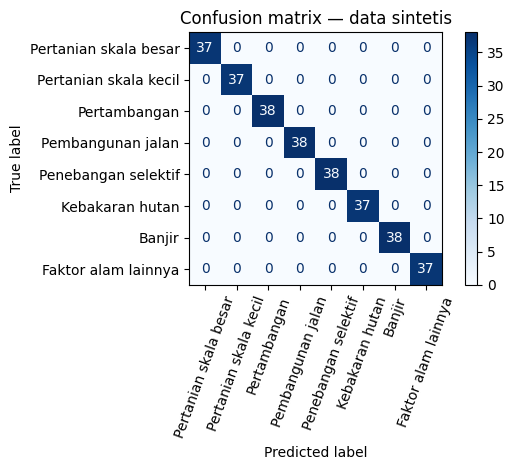

In [8]:
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=CLASS_NAMES,
    xticks_rotation=70,
    cmap="Blues",
    values_format="d"
)
plt.title("Confusion matrix — data sintetis")
plt.tight_layout()
plt.show()


## Langkah 8 — Prediksi satu patch dan tampilkan probabilitas

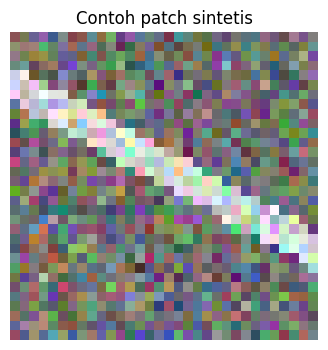

Prediksi: Pembangunan jalan
Probabilitas model: 0.915

Probabilitas semua kelas:
Pembangunan jalan            0.915
Pertanian skala kecil        0.084
Penebangan selektif          0.002
Pertanian skala besar        0.000
Banjir                       0.000
Pertambangan                 0.000
Faktor alam lainnya          0.000
Kebakaran hutan              0.000

CATATAN: probabilitas ini hanya keluaran model pada data sintetis, bukan kepastian penyebab di lapangan.


In [9]:
sample_index = 0
sample = X_test[sample_index]
probs = model.predict(sample[np.newaxis, ...], verbose=0)[0]
predicted_class = int(np.argmax(probs))

plt.figure(figsize=(4, 4))
plt.imshow(sample)
plt.title("Contoh patch sintetis")
plt.axis("off")
plt.show()

print("Prediksi:", CLASS_NAMES[predicted_class])
print("Probabilitas model:", f"{probs[predicted_class]:.3f}")
print("\nProbabilitas semua kelas:")
for name, p in sorted(zip(CLASS_NAMES, probs), key=lambda item: item[1], reverse=True):
    print(f"{name:28s} {p:.3f}")
print("\nCATATAN: probabilitas ini hanya keluaran model pada data sintetis, bukan kepastian penyebab di lapangan.")


## Langkah 9 — Simpan model dan label kelas

In [10]:
model.save("cnn_deforestation_synthetic.keras")

with open("class_names.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(CLASS_NAMES))

print("Model dan label kelas tersimpan di sesi Colab.")


Model dan label kelas tersimpan di sesi Colab.
